# 07 · Frozen July 2026 confirmation and Tableau exports

Run only after notebook 06 has frozen the model bundle. July outcomes must not change feature choices, settings, warning thresholds or the selected classifier. January–June 2026 are earlier exposed benchmarks.

**Scope:** 10,000 proportionally sampled July flights, natural prevalence, ATL/ORD/DFW, departure ≥15 minutes late, two-hour cutoff. July is the latest BTS month available when this experiment was declared. One summer month cannot establish year-round performance.

Compare all four selected B models, their retuned 66-feature references and matched-settings schedule-only A controls on **identical flights**. Quantify uncertainty with 300 paired day-block bootstraps, conditional on the fitted models. Report failures as well as improvements.

In [1]:
from pathlib import Path
import sys, json
from datetime import datetime, timezone
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve
from sklearn.svm import SVC

ROOT = Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
if (ROOT/'departure-delay-classification/config/project.json').exists(): ROOT/='departure-delay-classification'
sys.path.insert(0,str(ROOT/'scripts'))
from final_features import build_july_test
from final_modelling import MODELS, NAMES, sha, save, fingerprint, scores, metrics
from improvement_exports import make_tables
from baseline_integrity import verify_baseline_files
OUT = ROOT/'reports/final_models'
CONFIG = json.loads((ROOT/'config/project.json').read_text())
selection = json.loads((OUT/'selection.json').read_text())
assert 'bundle_frozen_at_utc' in selection, 'Finish notebook 06 first.'
assert sha(ROOT/selection['bundle_path'])==selection['bundle_sha256']
assert all(sha(ROOT/p)==v for p,v in selection['input_sha256'].items())
assert sha(OUT/'protocol.json')==selection['protocol_sha256']
assert sha(OUT/'development.json')==selection['development_sha256']
bundle = joblib.load(ROOT/selection['bundle_path'])
old_bundle = joblib.load(ROOT/'models/flight_delay_models.joblib')
assert bundle['run_id']==selection['run_id']
SELECTED = ('final',selection['selected_model_id'],'B')
RUN_ID = selection['run_id']
EXPORT = ROOT/'tableau/exports/final_july'
EXPORT.mkdir(exist_ok=True)
protocol = {'run_id':RUN_ID,'selection_sha256':sha(OUT/'selection.json'),
    'bundle_sha256':selection['bundle_sha256'],'period':['2026-07-01','2026-07-31'],
    'sample_rows':10000,'seed':42,'sampling':'proportional month x outcome, natural prevalence',
    'selected_before_test':list(SELECTED),'threshold_policy':'frozen October F1 thresholds',
    'bootstrap':{'repetitions':300,'seed':42,'unit':'flight-date blocks','paired':True,
        'comparisons':['B minus retuned66','B minus A'],'metrics':['F1','AP'],
        'scope':'conditional on fitted models, 31 observed calendar-day blocks'},
    'test_helpers':{p:sha(ROOT/p) for p in ['scripts/final_features.py','scripts/final_modelling.py',
        'scripts/improvement_exports.py','scripts/fresh_test_data.py',
        'reports/improvements/weather_quality.json','models/flight_delay_models.joblib']},
    'no_refitting_or_retuning':True}
for month in [4,5,6,7]:
    p=f'data/raw/flights/bts/2026/csv/2026_{month:02d}.csv'
    protocol.setdefault('raw_sha256',{})[p]=sha(ROOT/p)
for p in sorted((ROOT/'data/raw/weather/observations/2026').glob('*.csv')):
    protocol['raw_sha256'][p.relative_to(ROOT).as_posix()]=sha(p)
PROTOCOL_SHA = __import__('hashlib').sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()
access_path = OUT/'test_access.json'
if access_path.exists():
    access = json.loads(access_path.read_text())
    assert access['test_protocol_sha256']==PROTOCOL_SHA, 'July already exposed under another procedure.'
else:
    access = {'first_outcome_access_at_utc':datetime.now(timezone.utc).isoformat(),
        'test_protocol_sha256':PROTOCOL_SHA,'protocol':protocol}
    assert pd.Timestamp(access['first_outcome_access_at_utc'])>pd.Timestamp(selection['bundle_frozen_at_utc'])
    save(access_path,access)
sns.set_theme(style='whitegrid',palette=['#247BA0','#E08D3C','#5C946E','#8465A0'])
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
def table(x,**kw): print(x.to_string(**kw))
def plot(): plt.tight_layout(); plt.show()
print('Frozen selection:',SELECTED)
print('First July outcome access:',access['first_outcome_access_at_utc'])

Frozen selection: ('final', 'logistic_regression', 'B')
First July outcome access: 2026-10-19T06:28:21.545390+00:00


## Build the untouched evaluation cohort

The raw July schedule audit previously inspected no outcomes. We now apply the existing label/cleaning rules. Earlier April–June records supply historical context; July events can enter later July histories only after the seven-day lag. No July observations fit the classifier or preprocessing. Cancelled/unknown-label flights follow the unchanged exclusion rule; missing richer inputs do not remove flights.

In [2]:
quality = json.loads((ROOT/'reports/improvements/weather_quality.json').read_text())
approved = quality['excluded_station_times']
test,test_audit = build_july_test(ROOT,approved)
test = test.sort_values('flight_id').reset_index(drop=True)
y = test['delayed_departure'].to_numpy(dtype=int)
COHORT_SHA = fingerprint(test['flight_id'])
assert len(test)==10000 and test['flight_id'].is_unique
print('Scheduled / eligible July population:',test_audit['scheduled_july'],test_audit['eligible_july'])
print('Sample:',len(test),'| delayed:',int(y.sum()),'| prevalence:',round(y.mean(),4))
print('Missing matched weather, retained:',test_audit['weather_unmatched'])
from final_features import PRESSURE, SHAPES
table(test[PRESSURE+SHAPES].isna().mean().rename('missing_fraction').to_frame())
table(test.groupby('origin',observed=True)['delayed_departure'].agg(n='size',delayed='sum'))
evaluations, score_cache = [],{}
for m in MODELS:
    for fs in ['A','reference66','B']:
        item = bundle['models'][m+'__'+fs]
        cache_key = (id(item['pipeline']),tuple(item['columns']))
        if cache_key not in score_cache:
            started = perf_counter()
            s = scores(item['pipeline'],test[item['columns']])
            score_cache[cache_key] = (s,perf_counter()-started)
        s,elapsed = score_cache[cache_key]
        assert np.isfinite(s).all()
        evaluations.append({'version':'final','model_id':m,'feature_set':fs,'scores':s,
            'threshold':item['threshold'],'score_type':'svm_margin' if m=='svm' else 'uncalibrated_model_score',
            'prediction_seconds':elapsed,'fit_seconds':item['fit_seconds']})
        print(f'Scored {NAMES[m]}/{fs}: {elapsed:.2f}s',flush=True)

Scheduled / eligible July population: 89701 87298
Sample: 10000 | delayed: 3215 | prevalence: 0.3215
Missing matched weather, retained: 0
                             missing_fraction
altimeter_inhg                         0.0000
altimeter_change3h_inhg                0.0000
altimeter_range3h_inhg                 0.0000
variable_wind_flag                     0.0004
gust_excess_knots                      0.8605
altimeter_missing_flag                 0.0000
temperature_centered_square            0.0000
wind_square                            0.0004
dewpoint_spread_square                 0.0000
precip_log1p                           0.0000
ceiling_log1p                          0.5036
visibility_inverse                     0.0000
           n  delayed
origin               
ATL     3180     1060
DFW     3261     1156
ORD     3559      999
Scored Logistic Regression/A: 0.01s


Scored Logistic Regression/reference66: 0.02s


Scored Logistic Regression/B: 0.02s


Scored KNN/A: 6.23s


Scored KNN/reference66: 10.03s


...

Scored RBF SVM/reference66: 13.97s


Scored RBF SVM/B: 13.97s


Scored Random Forest/A: 0.06s


Scored Random Forest/reference66: 0.09s


Scored Random Forest/B: 0.10s


## Explicit baselines and all four model performances

Always-on-time accuracy can be high because most flights are on time, while its delayed-class F1 is zero. Always-delayed and a reproducible fair coin provide additional classification references. The historical ranking baseline uses the same lagged airline/origin history; its threshold/fallback are frozen from the original 2025 benchmark. Ranking does not use that threshold.

Fair coin expected F1 at this prevalence: 0.3914
           model_id  average_precision       f1  precision   recall  accuracy  predicted_positive   tp   fp  fn   tn
logistic_regression           0.566461 0.539544   0.380995 0.924106    0.4929                7798 2971 4827 244 1958
                knn           0.532373 0.545364   0.400701 0.853499    0.5425                6848 2744 4104 471 2681
                svm           0.512997 0.534197   0.434851 0.692379    0.6118                5119 2226 2893 989 3892
      random_forest           0.540385 0.542854   0.392560 0.879627    0.5237                7204 2828 4376 387 2409
Baselines:
               model_id  average_precision       f1  precision   recall  accuracy  predicted_positive   tp   fp   fn   tn
         always_on_time           0.321500 0.000000        NaN 0.000000    0.6785                   0    0    0 3215 6785
         always_delayed           0.321500 0.486568   0.321500 1.000000    0.3215               10000 3215 6785

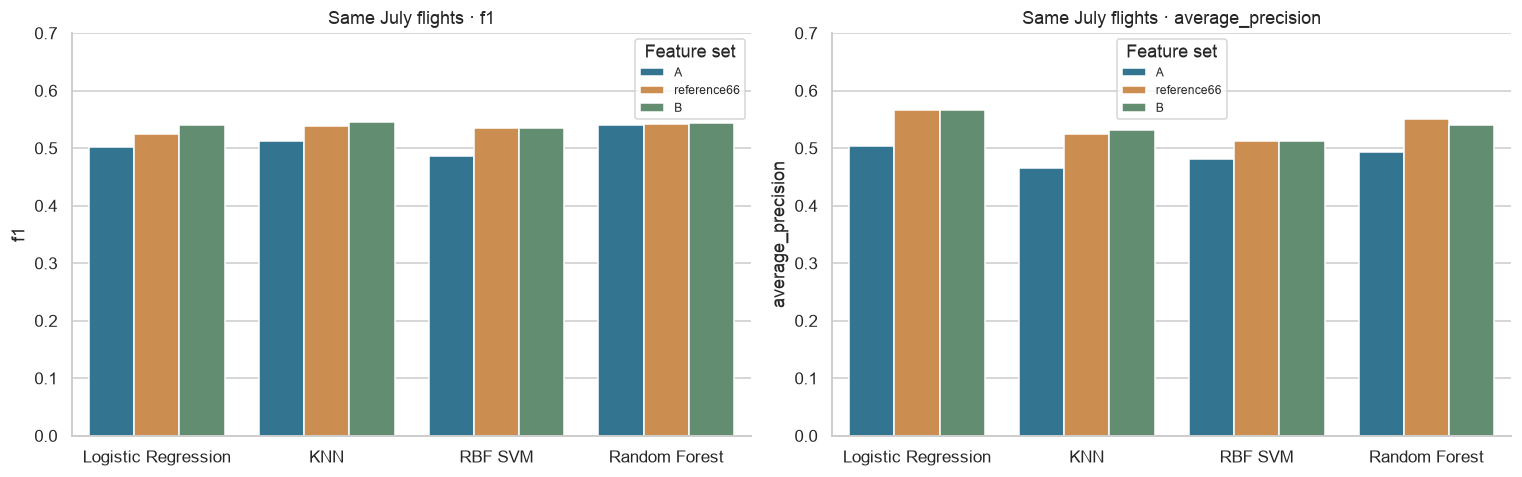

In [3]:
baseline_scores = {'always_on_time':np.zeros(len(test)),'always_delayed':np.ones(len(test)),
    'fair_coin_seed42':np.random.default_rng(42).integers(0,2,len(test)).astype(float),
    'historical_risk_ranking':test['history_airline_origin_rate'].fillna(test['history_origin_rate'])
        .fillna(old_bundle['historical_baseline_fallback']).to_numpy(dtype=float)}
for name,s in baseline_scores.items():
    t = old_bundle['baseline_thresholds']['historical_risk_ranking'] if name=='historical_risk_ranking' else .5
    evaluations.append({'version':'baseline','model_id':name,'feature_set':'baseline','scores':s,
        'threshold':t,'score_type':'baseline_score'})
tables = make_tables(test,evaluations,CONFIG,RUN_ID,SELECTED,COHORT_SHA)
for frame in tables.values():
    if 'split' in frame: frame['split']='test_july_2026'
mm = tables['model_metrics.csv']
for key,item in bundle['models'].items():
    m,fs = key.split('__')
    mask = mm.model_id.eq(m)&mm.feature_set.eq(fs)
    mm.loc[mask,'feature_package'] = item['package']
    mm.loc[mask,'n_predictors'] = len(item['columns'])
    mm.loc[mask,'preprocessing_recipe'] = item['recipe']
    mm.loc[mask,'hyperparameters'] = json.dumps(item['params'],sort_keys=True)
for i,r in tables['feature_comparison.csv'].iterrows():
    item = bundle['models'][r['model_id']+'__B']
    tables['feature_comparison.csv'].loc[i,'added_feature_package'] = item['package']
    tables['feature_comparison.csv'].loc[i,'base_predictors'] = len(bundle['models'][r['model_id']+'__A']['columns'])
    tables['feature_comparison.csv'].loc[i,'added_predictors'] = len(item['columns'])
    tables['feature_comparison.csv'].loc[i,'coverage_definition'] = 'Weather report matched and origin history nonzero; not complete weather measurements'
    tables['feature_comparison.csv'].loc[i,'weather_report_match_fraction'] = test['weather_report_missing'].eq(0).mean()
    tables['feature_comparison.csv'].loc[i,'origin_history_available_fraction'] = test['history_origin_n'].gt(0).mean()
print('Fair coin expected F1 at this prevalence:',round(float(y.mean()/(y.mean()+.5)),4))
b = mm.loc[mm.feature_set.eq('B')].copy()
cols = ['model_id','average_precision','f1','precision','recall','accuracy','predicted_positive','tp','fp','fn','tn']
table(b[cols],index=False)
print('Baselines:')
table(mm.loc[mm.model_version.eq('baseline'),cols],index=False)
fig,axes = plt.subplots(1,2,figsize=(14,4.5))
compare = mm.loc[mm.model_version.eq('final')]
for metric,ax in zip(['f1','average_precision'],axes):
    sns.barplot(data=compare,x='model_id',y=metric,hue='feature_set',ax=ax)
    ax.set(title='Same July flights · '+metric,xlabel='',ylim=(0,.7))
    ax.set_xticks(ax.get_xticks(),['Logistic Regression','KNN','RBF SVM','Random Forest'])
    ax.legend(title='Feature set',fontsize=8)
plot()

## Paired uncertainty: new features and richer information

We compare B with the equally retuned 66-feature reference to assess the compact additions, and B with matched-settings A for O2. Resample entire July dates rather than independent flights. These intervals describe this month's sampling variability conditional on the fitted models; 31 day blocks give limited evidence about other seasons.

           model_id          comparison   ap_gain    ap_low   ap_high  f1_gain    f1_low  f1_high
logistic_regression B minus reference66  0.000624 -0.005938  0.006530 0.015038  0.011492 0.019267
logistic_regression           B minus A  0.062337  0.038954  0.084748 0.038317  0.033006 0.044319
                knn B minus reference66  0.008401  0.002834  0.013305 0.006155  0.001826 0.010087
                knn           B minus A  0.066627  0.045641  0.088992 0.032168  0.026556 0.036913
                svm B minus reference66  0.000000  0.000000  0.000000 0.000000  0.000000 0.000000
                svm           B minus A  0.031193  0.016453  0.049012 0.047629  0.036157 0.060452
      random_forest B minus reference66 -0.009966 -0.014362 -0.005531 0.001072 -0.001831 0.003890
      random_forest           B minus A  0.047576  0.033884  0.063282 0.002341 -0.003328 0.007940


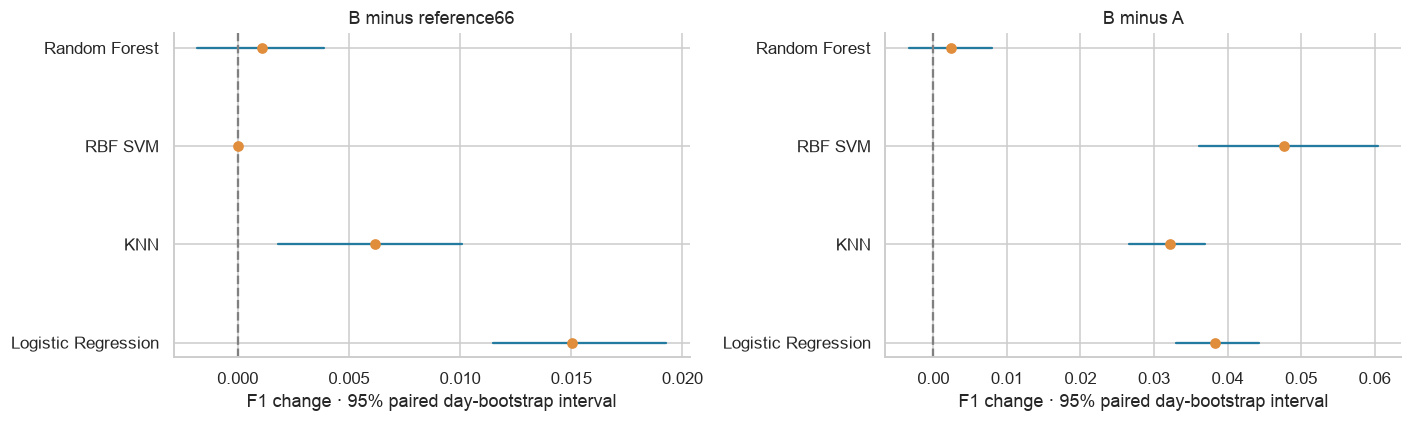

In [4]:
score_map = {(e['model_id'],e['feature_set']):e for e in evaluations if e['version']=='final'}
day_codes,days = pd.factorize(test['flight_date'],sort=True)
rng = np.random.default_rng(42)
weights = [np.bincount(rng.integers(0,len(days),len(days)),minlength=len(days))[day_codes] for _ in range(300)]
paired = []
for m in MODELS:
    new = score_map[(m,'B')]
    for reference in ['reference66','A']:
        old = score_map[(m,reference)]
        differences = {'ap':[],'f1':[]}
        for w in weights:
            differences['ap'].append(average_precision_score(y,new['scores'],sample_weight=w)-average_precision_score(y,old['scores'],sample_weight=w))
            f = []
            for e in [new,old]:
                pred = e['scores']>=e['threshold']
                tp = w[(y==1)&pred].sum();fp=w[(y==0)&pred].sum();fn=w[(y==1)&~pred].sum()
                f.append(2*tp/(2*tp+fp+fn))
            differences['f1'].append(f[0]-f[1])
        row = {'model_id':m,'comparison':'B minus '+reference}
        for metric in ['ap','f1']:
            field = 'average_precision' if metric=='ap' else 'f1'
            pair = mm.loc[mm.model_id.eq(m)].set_index('feature_set')
            row[metric+'_gain'] = float(pair.loc['B',field]-pair.loc[reference,field])
            low,high = np.quantile(differences[metric],[.025,.975])
            row[metric+'_low'],row[metric+'_high'] = float(low),float(high)
        paired.append(row)
paired_table = pd.DataFrame(paired)
table(paired_table,index=False)
fig,axes = plt.subplots(1,2,figsize=(13,4))
for comparison,ax in zip(['B minus reference66','B minus A'],axes):
    block = paired_table.loc[paired_table.comparison.eq(comparison)].reset_index(drop=True)
    for i,r in block.iterrows():
        ax.plot([r.f1_low,r.f1_high],[i,i],color='#247BA0')
        ax.scatter(r.f1_gain,i,color='#E08D3C',zorder=3)
    ax.axvline(0,color='grey',linestyle='--')
    ax.set(yticks=range(4),yticklabels=[NAMES[m] for m in block.model_id],
        xlabel='F1 change · 95% paired day-bootstrap interval',title=comparison)
plot()

## O1 and O3 · Frozen selected model and its errors

The selected classifier remains the 2025 validation choice, even if another July bar is higher. Subgroup precision/recall/error rates obey the original minimum-support rules; unsupported rates remain blank.

Validation-selected model: Logistic Regression
average_precision     0.566461
f1                    0.539544
precision             0.380995
recall                0.924106
accuracy                0.4929
predicted_positive        7798
tp                        2971
fp                        4827
fn                         244
tn                        1958


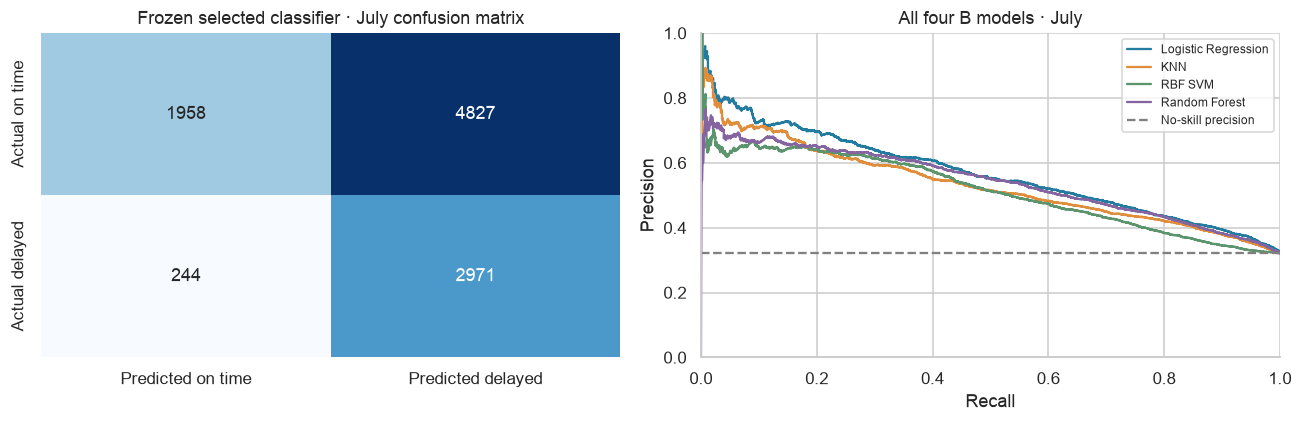

        group_dimension      group_value  n_flights  precision    recall  false_positive_rate
36               origin              ATL       3180   0.413174  0.911321             0.647170
37               origin              DFW       3261   0.416347  0.938581             0.722565
38               origin              ORD       3559   0.322355  0.920921             0.755469
39    reporting_airline               AA       2398   0.473731  0.972578             0.906442
40    reporting_airline               AS         91        NaN       NaN                  NaN
41    reporting_airline               B6         66        NaN       NaN                  NaN
42    reporting_airline               DL       2701   0.392764  0.895933             0.620912
43    reporting_airline               F9        389   0.411111  1.000000             0.879668
44    reporting_airline               MQ       1310   0.272277  0.839695             0.561069
45    reporting_airline               OH        214   0.4012

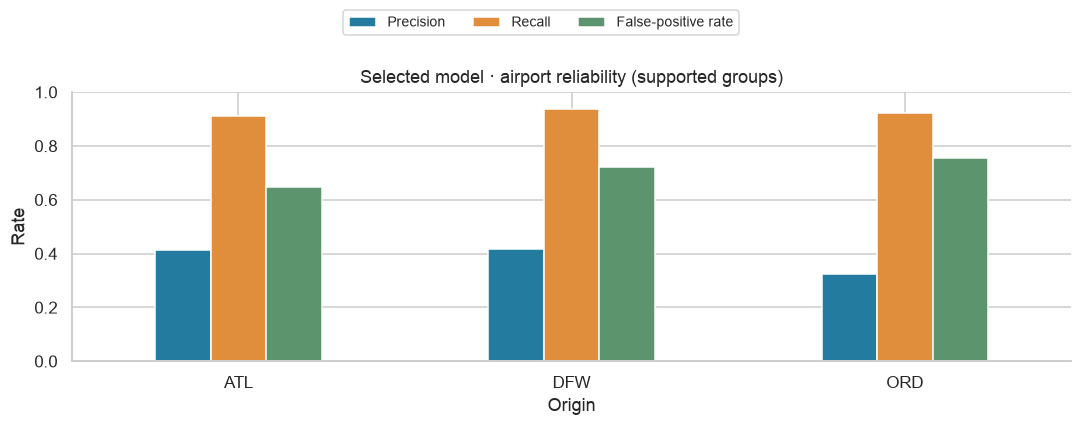

In [5]:
selected_row = mm.loc[mm.is_validation_selected].iloc[0]
selected_e = score_map[(selection['selected_model_id'],'B')]
print('Validation-selected model:',NAMES[selection['selected_model_id']])
table(selected_row[cols[1:]])
fig,axes = plt.subplots(1,2,figsize=(12,4))
sns.heatmap(np.array([[selected_row.tn,selected_row.fp],[selected_row.fn,selected_row.tp]],dtype=int),
    annot=True,fmt='d',cmap='Blues',cbar=False,ax=axes[0],
    xticklabels=['Predicted on time','Predicted delayed'],yticklabels=['Actual on time','Actual delayed'])
axes[0].set_title('Frozen selected classifier · July confusion matrix')
for m in MODELS:
    p,r,_ = precision_recall_curve(y,score_map[(m,'B')]['scores'])
    axes[1].plot(r,p,label=NAMES[m])
axes[1].axhline(y.mean(),color='grey',linestyle='--',label='No-skill precision')
axes[1].set(xlabel='Recall',ylabel='Precision',title='All four B models · July',xlim=(0,1),ylim=(0,1))
axes[1].legend(fontsize=8)
plot()
subgroups = tables['subgroup_metrics.csv']
selected_groups = subgroups.loc[subgroups.model_id.eq(selection['selected_model_id'])&subgroups.feature_set.eq('B')]
table(selected_groups[['group_dimension','group_value','n_flights','precision','recall','false_positive_rate']])
fig,ax = plt.subplots(figsize=(10,3.5))
airports = selected_groups.loc[selected_groups.group_dimension.eq('origin')]
airports.set_index('group_value')[['precision','recall','false_positive_rate']].plot.bar(ax=ax)
ax.set(title='Selected model · airport reliability (supported groups)',ylabel='Rate',xlabel='Origin',ylim=(0,1))
ax.tick_params(axis='x',rotation=0)
handles,labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
fig.legend(handles,['Precision','Recall','False-positive rate'],loc='upper center',bbox_to_anchor=(.5,1.12),ncol=3,fontsize=9)
plot()

## O4 · Does a limited review list concentrate delayed flights?

Review quotas were fixed at 5%, 10% and 20%. This retrospective ranking exercise uses the full evaluation cohort and outcome-independent hash tie-breaking. It measures prioritization, not prevented delays or operational savings.

               model_id  capacity_fraction  reviewed_flights  captured_delays  false_alerts  capture_recall  review_precision  lift_over_prevalence
    logistic_regression               0.05               500              359           141        0.111664             0.718              2.233281
    logistic_regression               0.10              1000              688           312        0.213997             0.688              2.139969
    logistic_regression               0.20              2000             1222           778        0.380093             0.611              1.900467
historical_risk_ranking               0.05               500              221           279        0.068740             0.442              1.374806
historical_risk_ranking               0.10              1000              442           558        0.137481             0.442              1.374806
historical_risk_ranking               0.20              2000              918          1082        0.285537     

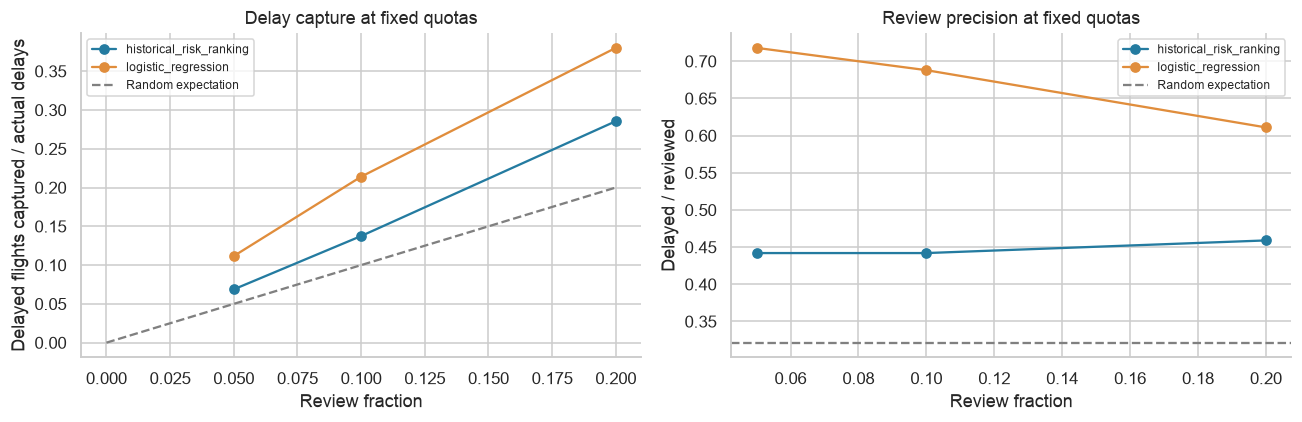

In [6]:
priority = tables['priority_curve.csv']
selected_priority = priority.loc[(priority.model_version.eq('final')&priority.model_id.eq(selection['selected_model_id'])&priority.feature_set.eq('B'))|
    (priority.model_version.eq('baseline')&priority.model_id.eq('historical_risk_ranking'))]
table(selected_priority[['model_id','capacity_fraction','reviewed_flights','captured_delays','false_alerts','capture_recall','review_precision','lift_over_prevalence']],index=False)
fig,axes = plt.subplots(1,2,figsize=(12,4))
for name,block in selected_priority.groupby('model_id',observed=True):
    axes[0].plot(block.capacity_fraction,block.capture_recall,marker='o',label=name)
    axes[1].plot(block.capacity_fraction,block.review_precision,marker='o',label=name)
axes[0].plot([0,.2],[0,.2],linestyle='--',color='grey',label='Random expectation')
axes[1].axhline(y.mean(),linestyle='--',color='grey',label='Random expectation')
axes[0].set(xlabel='Review fraction',ylabel='Delayed flights captured / actual delays',title='Delay capture at fixed quotas')
axes[1].set(xlabel='Review fraction',ylabel='Delayed / reviewed',title='Review precision at fixed quotas')
for ax in axes: ax.legend(fontsize=8)
plot()

## Reconcile outputs and save six Tableau sources

Keep separate data sources at their declared grains. Never join global model metrics onto every prediction row and sum them. A dashboard must select one candidate before counting flights. Risk scores are not calibrated probabilities. The existing Q1 and Q2 export folders are preserved.

In [7]:
predictions = tables['flight_predictions.csv']
# Reconcile every exported confusion matrix and review quota to row-level predictions.
for _,r in mm.iterrows():
    p = predictions.loc[predictions.candidate_id.eq(r.candidate_id)]
    assert len(p)==10000 and p.flight_id.nunique()==10000
    assert fingerprint(p.flight_id)==COHORT_SHA
    tn,fp,fn,tp = confusion_matrix(p.y_true,p.y_pred,labels=[0,1]).ravel()
    assert [tn,fp,fn,tp]==[r.tn,r.fp,r.fn,r.tp]
for _,r in priority.iterrows():
    p = predictions.loc[predictions.candidate_id.eq(r.candidate_id)].sort_values('risk_rank').head(int(r.reviewed_flights))
    assert int(p.y_true.sum())==r.captured_delays
for r in paired:
    mask = mm.model_id.eq(r['model_id'])&mm.feature_set.eq('B')
    prefix = 'vs66_' if r['comparison']=='B minus reference66' else 'vsA_'
    for k,v in r.items():
        if k not in ['model_id','comparison']: mm.loc[mask,prefix+k]=v
files = {}
for name,frame in tables.items():
    p = EXPORT/name
    frame.to_csv(p,index=False)
    files[name] = {'rows':len(frame),'sha256':sha(p),'bytes':p.stat().st_size}
assert sha(OUT/'selection.json')==protocol['selection_sha256']
assert sha(ROOT/selection['bundle_path'])==selection['bundle_sha256']
assert all(sha(ROOT/p)==v for p,v in protocol['raw_sha256'].items())
integrity = verify_baseline_files(ROOT,json.loads((ROOT/'reports/improvements/baseline_fingerprints.json').read_text()))
manifest = dict(run_id=RUN_ID,test_period=['2026-07-01','2026-07-31'],test_rows=10000,
    selected_before_test=list(SELECTED),cohort_fingerprint=COHORT_SHA,files=files,
    selection_sha256=protocol['selection_sha256'],test_protocol_sha256=PROTOCOL_SHA,
    scope_note='One summer month, three hubs; natural prevalence; historical simulation with assumed availability.',
    tableau_filters={'model_version':'final','feature_set':'B','threshold_policy':'F1'},
    workbook_selected_model=selection['selected_model_id'],baseline_content_integrity=integrity)
save(EXPORT/'export_manifest.json',manifest)
results = dict(run_id=RUN_ID,completed_at_utc=datetime.now(timezone.utc).isoformat(),
    selected_before_test=list(SELECTED),test_audit=test_audit,actual_delays=int(y.sum()),
    cohort_fingerprint=COHORT_SHA,metrics=json.loads(mm.to_json(orient='records')),
    paired_comparisons=paired,selected_priority=json.loads(selected_priority.to_json(orient='records')),
    settings_changed_after_test=False,baseline_content_integrity=integrity)
save(OUT/'test_results.json',results)
print('Saved six versioned Tableau CSVs:',EXPORT.relative_to(ROOT))
print('All prediction, confusion and quota reconciliations passed. No July-driven retuning.')

Saved six versioned Tableau CSVs: tableau/exports/final_july
All prediction, confusion and quota reconciliations passed. No July-driven retuning.


## Interpretation rules

- Report F1, AP, precision, recall and false-warning counts together. F1 is not accuracy and has no universal coin-flip cutoff of 0.50.
- A positive feature gain whose interval crosses zero is weak evidence of improvement in this month. A negative gain stays in the results.
- Keep the validation-selected model separate from the highest July test score. Do not retune after seeing July.
- Favor a limited ranking claim if the warning threshold transfers poorly but the top review quotas still concentrate delays.
- The four Tableau dashboards use this frozen run: O1 performance, O2 matched A/B feature value, O3 supported prediction-error groups, O4 review-quota usefulness.

## Measured conclusion

The frozen 2025 validation choice is **Logistic Regression** with `combined`. On July it achieved **F1 0.540**, **precision 0.381**, **recall 0.924**, and **AP 0.566**. Its 7,798 warnings included **4,827 false warnings**, and it missed **244 delays**.

The results support a measured comparison of the four basic classifiers, rather than a claim that extra features guarantee strong delay prediction. Read the paired intervals and review-quota results above before claiming improvement or usefulness. Full findings: `reports/final_models/RESULTS.md`.

At the predeclared 10% review quota, Logistic Regression found **688 delayed flights among 1,000 reviewed (68.8% precision, 2.14× random lift)**; historical ranking found 442. Its compact-feature F1 gain against the retuned 66-feature reference was **+0.015**, while its AP gain was negligible. Improvements were mixed across models. The full warning policy still produced 4,827 false alerts.